[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/user/repo/blob/main/notebook.ipynb)

# Lecture 13
# Uncertainty partitioning for CMIP6 global mean temperature
- F : forced response of each model   (4th-order polynomial fit)
- I : internal variability            (variance of residual = data - F)
- M : model uncertainty               (variance across models of F)
- S : scenario uncertainty            (variance across scenario means of F)

In [1]:
#global annual temperature data from cmip6
import numpy as np
import pandas as pd
import statsmodels.api as sm #linear regression
import matplotlib.pyplot as plt

scenarios = ["ssp126", "ssp245", "ssp370", "ssp585"]

## 1. Read data: one file per scenario, rows = years, columns = models

In [4]:
data = {}
for s in scenarios:
    df = pd.read_csv(f"cmip6_{s}.csv", index_col="year")
    # anomaly relative to 1995-2014
    df = df - df.loc[1995:2014].mean()
    data[s] = df #data is an empty list
models = data["ssp585"].columns #how many models
years = data["ssp585"].index.values #how many years



##  2. Forced response F: 4th-order polynomial fit for each model/scenario

- Standardize time (predictors)
- create predictors: x, x2, x3, x4
- conducting fit to get the fitted trend

### 2.1 For one scneario, one model  - review trend and residual

In [5]:
# rescaled time for a stable fit
x = (years - years.mean()) / years.std()
# columns: 1, x, x², x³, x⁴ (predictors)
X = np.column_stack([x**k for k in range(4 + 1)])   # columns: 1, x, x², x³, x⁴
X[0,:]

#1st column is 1 and then the four predictors for year 1

array([ 1.        , -1.72054204,  2.9602649 , -5.0932602 ,  8.76316828])

In [6]:
#look at data - temp anomalies
Data1 = data["ssp585"]['cmip6_M01']
Data1

,cmip6_M01
year,
1950,-0.804815
1951,-0.830215
1952,-0.886815
1953,-0.878515
1954,-0.994615
...,...
2095,5.004985
2096,5.001385
2097,5.004585


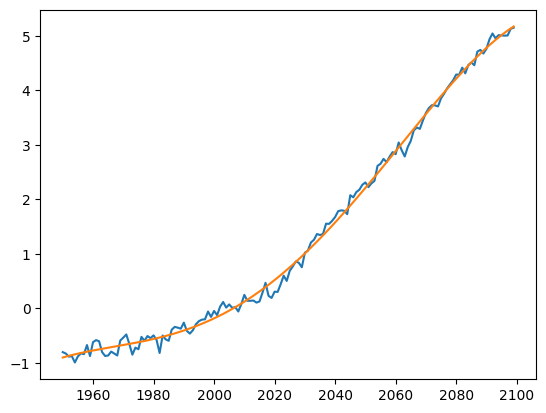

In [7]:
# get global mean T from a single model under rssp585 and apply OLS fit
Data1 = data["ssp585"]['cmip6_M01']
res = sm.OLS(Data1.values, X).fit() #five predictors
Data1_fit  = res.fittedvalues
plt.plot(years, Data1)
plt.plot(years, Data1_fit)

#blue line is original, orange is fitted

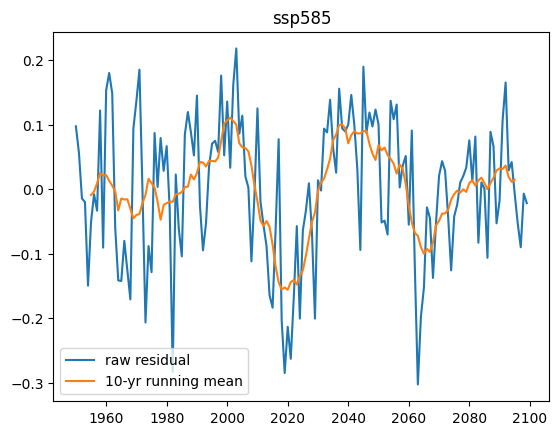

In [10]:
# get residual and apply 10-yr running mean (using panda array function)
resid = (data[s]['cmip6_M01'] - Data1_fit).rolling(10, center=True).mean() #10 year running mean
plt.plot(years,data[s]['cmip6_M01'] - Data1_fit, label = 'raw residual') #plot residual
plt.plot(years,resid, label = '10-yr running mean')
plt.title(s)
plt.legend()

### 2.2 For multiple models and multiple scenarios (F, I, M, S)

In [11]:

F = {} #empty dataset
for s in scenarios:
    F[s] = pd.DataFrame(index=years, columns=models, dtype=float)
    for m in models:
        res = sm.OLS(data[s][m].values, X).fit()
        F[s][m] = res.fittedvalues
    ### all forced responses is reletive to 1995 to 2014 mean (optional)
    F[s] = F[s] - F[s].loc[1995:2014].mean()

Text(0.5, 1.0, 'ssp585')

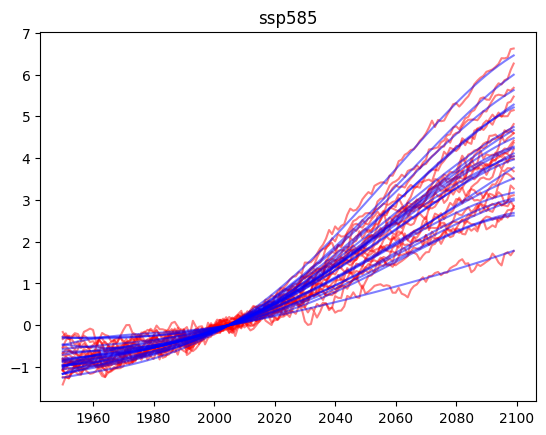

In [12]:
### check results using the last ssp in the scnearios
plt.plot(years,data[s],'r',alpha=0.5); #s is the ssp585 here
plt.plot(years,F[s],'b',alpha=0.5); #forced signal
plt.title(s)
#centered around 2005

### 3. Internal variability I
 one number per model and scenario, then average all of them

In [13]:
#create internal variability and run through scenarios, look at residuals
I_values = []
for s in scenarios:
    resid = (data[s] - F[s]).rolling(10, center=True).mean()
    I_values.extend(resid.var(axis=0))          # variance over time, per model
I = np.mean(I_values)                           # single number (K^2), constant in time
print(I)
#assumes internal variability is constant in time

0.003227054911943948


### 4. Model uncertainty M: variance across models of F (SSP5-8.5), each year

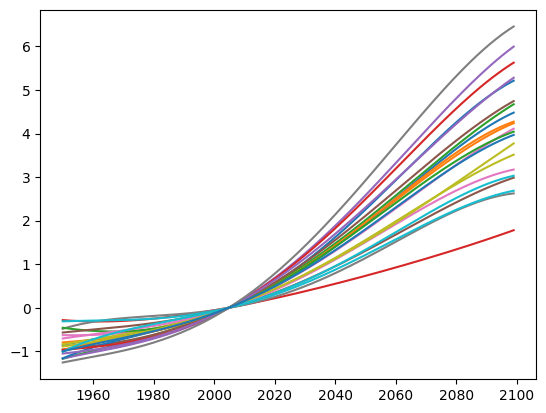

In [14]:
#model uncertainty is the variance across lines
plt.plot(F["ssp585"]);

In [15]:
M = F["ssp585"].var(axis=1, ddof=0) # population; CMIP6 is an ensmelbe of possibility not a random sample of all possible models.
print(M)

1950    0.078083
1951    0.074661
1952    0.071511
1953    0.068604
1954    0.065913
          ...   
2095    1.256913
2096    1.280301
2097    1.303380
2098    1.326126
2099    1.348519
Length: 150, dtype: float64


###  5. Scenario uncertainty S: variance across the multimodel mean of each scenario

1950    0.000299
1951    0.000231
1952    0.000267
1953    0.000379
1954    0.000546
          ...   
2095    1.640979
2096    1.685512
2097    1.729582
2098    1.773085
2099    1.815916
Length: 150, dtype: float64


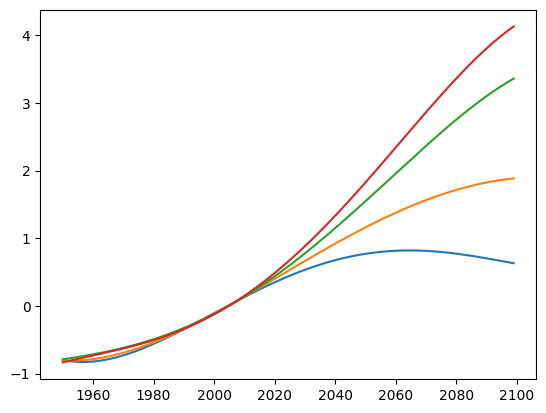

In [17]:
#calculate scenario mean for each scenario and average it
scen_means = pd.DataFrame({s: F[s].mean(axis=1) for s in scenarios})
S = scen_means.var(axis=1, ddof=0)
plt.plot(scen_means);
print(S)

#one line per scenario, calculate variance across the four lines

### 6. Fractions of total variance T = I + M + S

In [18]:

T = I + M + S
frac = pd.DataFrame({"Internal": I / T, "Model": M / T, "Scenario": S / T}) * 100

In [19]:
frac #contibution of each term

,Internal,Model,Scenario
1950,3.954266,95.679266,0.366469
1951,4.130932,95.573199,0.295869
1952,4.302476,95.341892,0.355631
1953,4.468983,95.005785,0.525231
1954,4.630822,94.585789,0.783389
...,...,...,...
2095,0.111235,43.325103,56.563662
2096,0.108690,43.121717,56.769593
2097,0.106286,42.928158,56.965556
2098,0.104017,42.744645,57.151338


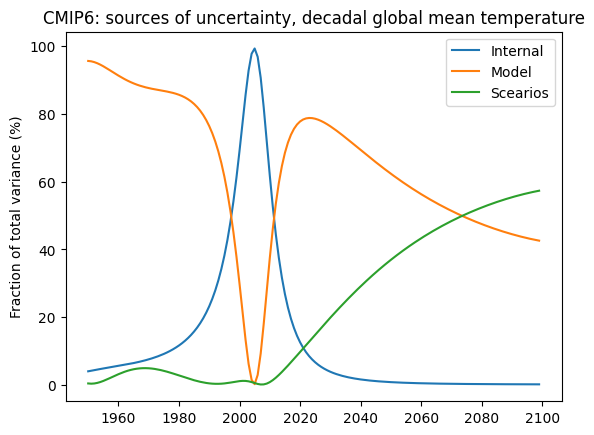

In [20]:
#internal variability is highest where it is centered
plt.plot(years,frac['Internal'],label = 'Internal')
plt.plot(years,frac['Model'],label = "Model")
plt.plot(years,frac['Scenario'],label = "Scearios")
plt.title("CMIP6: sources of uncertainty, decadal global mean temperature")
plt.legend()
plt.ylabel("Fraction of total variance (%)")
plt.xlim()
plt.savefig('CMIP6.png',dpi = 200)

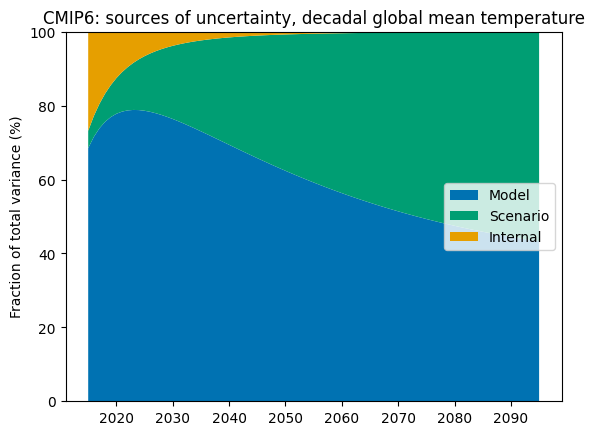

In [21]:

# simple plot of the fractions, 2015-2095
f = frac.loc[2015:2095] #projection period
plt.stackplot(f.index, f["Model"], f["Scenario"], f["Internal"],
              labels=["Model", "Scenario", "Internal"],
              colors=["#0072B2", "#009E73", "#E69F00"])
plt.ylim(0, 100)
plt.ylabel("Fraction of total variance (%)")
plt.title("CMIP6: sources of uncertainty, decadal global mean temperature")
plt.legend(loc="center right")
plt.savefig("cmip6_fractions.png", dpi=150)
plt.show()

#you can also look directly at fractional frac.loc[2015] but this is a fancy plot

In [ ]:
print(f"Internal fraction 2050 (%): {frac.loc[2050, 'Internal']:.3f}")
print(f"Model fraction 2050 (%): {frac.loc[2050, 'Model']:.3f}")

Internal fraction 2050 (%): 1.074
Model fraction 2050 (%): 56.051


## Signal-to-noise ratio
- Signal G(t) = multimodel, multi-scenario mean change (mean of scen_means)
- Noise       = 90% half-width of the uncertainty, 1.645 * sqrt(variance)
- S/N > 1     : expected change exceeds the 90% uncertainty range

In [ ]:

G = scen_means.mean(axis=1)

SN_total = G / (1.645 * np.sqrt(I + M + S))     # all three sources
SN_noModel = G / (1.645 * np.sqrt(I + S))       # if model uncertainty were removed
SN_internal = G / (1.645 * np.sqrt(I))          # vs. internal variability only

(2015.0, 2100.0)

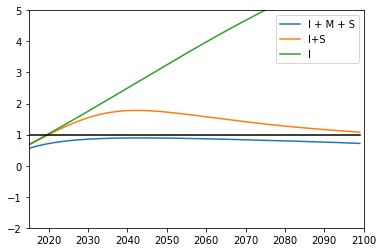

In [ ]:
plt.plot(years,SN_total,label='I + M + S')
plt.plot(years,SN_noModel,label ='I+S')
plt.plot(years,SN_internal,label = 'I')
plt.plot(years,years*0+1,'k')
plt.legend()
plt.ylim([-2,5])
plt.xlim([2015,2100])

# Hands-on

In [29]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [31]:
scenarios = ["ssp126", "ssp245", "ssp370", "ssp585"]

# 1. Read data (rows = years, columns = models) and make anomalies
data = {}
for s in scenarios:
    df = pd.read_csv(f"/content/cmip6_britishisles_tas_{s}.csv", index_col="year")
    data[s] = df - df.loc[1995:2014].mean()      # anomaly relative to 1995-2014

In [35]:

data[s] = df #data is an empty list
models = data["ssp126"].columns #how many models
years = data["ssp126"].index.values #how many years

In [36]:
# rescaled time for a stable fit
x = (years - years.mean()) / years.std()
# columns: 1, x, x², x³, x⁴ (predictors)
X = np.column_stack([x**k for k in range(4 + 1)])   # columns: 1, x, x², x³, x⁴
X[0,:]

#1st column is 1 and then the four predictors for year 1

array([ 1.        , -1.72054204,  2.9602649 , -5.0932602 ,  8.76316828])

In [37]:
#look at data - temp anomalies
Data1 = data["ssp126"]['cmip6_M01']
Data1

,cmip6_M01
year,
1950,10.7378
1951,9.3292
1952,9.2664
1953,10.4859
1954,10.2996
...,...
2095,14.7068
2096,14.9315
2097,15.3198


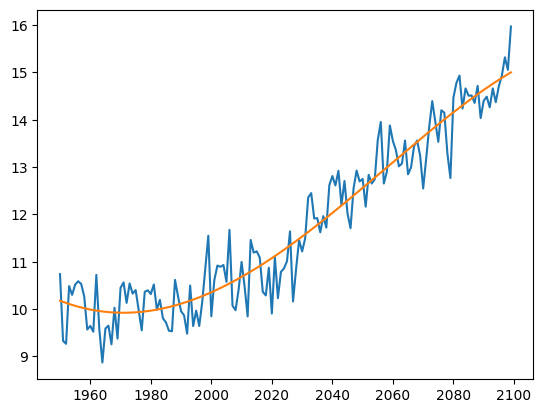

In [38]:
# get global mean T from a single model under rssp585 and apply OLS fit
Data1 = data["ssp126"]['cmip6_M01']
res = sm.OLS(Data1.values, X).fit() #five predictors
Data1_fit  = res.fittedvalues
plt.plot(years, Data1)
plt.plot(years, Data1_fit)

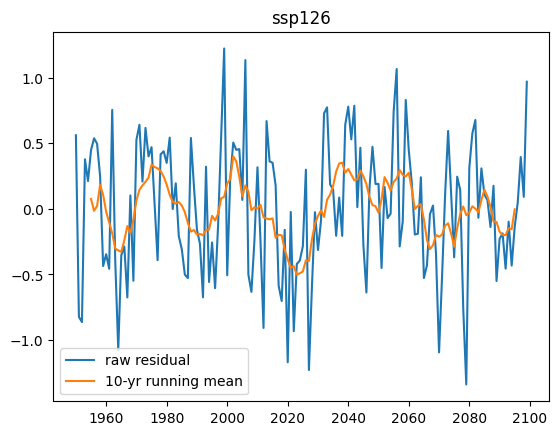

In [39]:
# get residual and apply 10-yr running mean (using panda array function)
resid = (data[s]['cmip6_M01'] - Data1_fit).rolling(10, center=True).mean() #10 year running mean
plt.plot(years,data[s]['cmip6_M01'] - Data1_fit, label = 'raw residual') #plot residual
plt.plot(years,resid, label = '10-yr running mean')
plt.title(s)
plt.legend()